In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

from torch.utils.data import DataLoader, Subset
from torchvision.datasets import CIFAR10

import matplotlib.pyplot as plt
import numpy as np
import random
import time
import copy

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cpu


In [3]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Both transformation pipelines created successfully.")

Both transformation pipelines created successfully.


100.0%


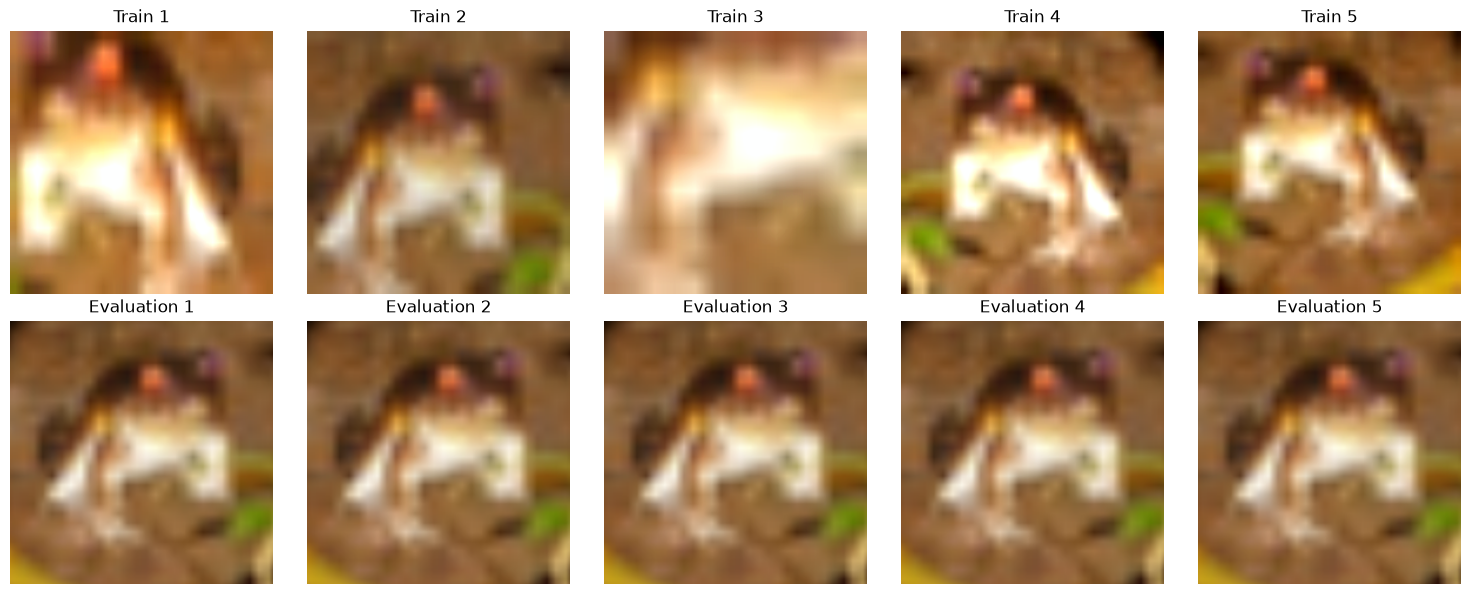

In [4]:
dataset = CIFAR10(
    root="./data",
    train=True,
    download=True
)

image, label = dataset[0]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i in range(5):
    img = train_transform(image)
    img = img.permute(1, 2, 0).numpy()
    axes[0, i].imshow(np.clip(
        img * np.array([0.229, 0.224, 0.225]) +
        np.array([0.485, 0.456, 0.406]), 0, 1
    ))
    axes[0, i].set_title(f"Train {i+1}")
    axes[0, i].axis("off")

for i in range(5):
    img = eval_transform(image)
    img = img.permute(1, 2, 0).numpy()
    axes[1, i].imshow(np.clip(
        img * np.array([0.229, 0.224, 0.225]) +
        np.array([0.485, 0.456, 0.406]), 0, 1
    ))
    axes[1, i].set_title(f"Evaluation {i+1}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [5]:
train_dataset = CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

val_dataset = CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=eval_transform
)

classes = train_dataset.classes

print("Classes:", classes)
print("Total images:", len(train_dataset))

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Total images: 50000


In [6]:
random.seed(SEED)

indices = list(range(5000))
random.shuffle(indices)

train_indices = indices[:4000]
val_indices = indices[4000:]

train_data = Subset(train_dataset, train_indices)
val_data = Subset(val_dataset, val_indices)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))

Training images: 4000
Validation images: 1000


In [8]:
BATCH_SIZE = 32

def create_loaders():
    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_data,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_data,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    return train_loader, val_loader



In [9]:
NUM_CLASSES = 10

def create_model():
    model = models.resnet18(
        weights=models.ResNet18_Weights.IMAGENET1K_V1
    )

    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    return model

In [10]:
feature_model = create_model()

for param in feature_model.parameters():
    param.requires_grad = False

for param in feature_model.fc.parameters():
    param.requires_grad = True

feature_model = feature_model.to(device)

trainable_params = sum(
    p.numel() for p in feature_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_params)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\abhim/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Trainable parameters: 5130


In [11]:
EPOCHS = 5

def train_model(model, optimizer, train_loader, val_loader,
                frozen=False):

    criterion = nn.CrossEntropyLoss()

    start_time = time.time()

    for epoch in range(EPOCHS):

        model.train()

        if frozen:
            model.eval()
            model.fc.train()

        running_loss = 0.0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(
            f"Epoch [{epoch+1}/{EPOCHS}], "
            f"Loss: {running_loss / len(train_loader):.4f}"
        )

    training_time = time.time() - start_time

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    return accuracy, training_time

In [12]:
train_loader, val_loader = create_loaders()

feature_optimizer = optim.Adam(
    feature_model.fc.parameters(),
    lr=0.001
)

feature_accuracy, feature_time = train_model(
    feature_model,
    feature_optimizer,
    train_loader,
    val_loader,
    frozen=True
)

feature_params = sum(
    p.numel() for p in feature_model.parameters()
    if p.requires_grad
)

print("\nFeature Extraction Results")
print("Validation Accuracy:", feature_accuracy, "%")
print("Training Time:", round(feature_time, 2), "seconds")
print("Trainable Parameters:", feature_params)

Epoch [1/5], Loss: 1.5563
Epoch [2/5], Loss: 1.1229
Epoch [3/5], Loss: 1.0277
Epoch [4/5], Loss: 1.0001
Epoch [5/5], Loss: 0.9427

Feature Extraction Results
Validation Accuracy: 78.8 %
Training Time: 859.61 seconds
Trainable Parameters: 5130


In [13]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

fine_model = create_model()

for param in fine_model.parameters():
    param.requires_grad = False

for param in fine_model.layer4.parameters():
    param.requires_grad = True

for param in fine_model.fc.parameters():
    param.requires_grad = True

fine_model = fine_model.to(device)

fine_params = sum(
    p.numel() for p in fine_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", fine_params)

Trainable parameters: 8398858


In [14]:
fine_optimizer = optim.Adam([
    {
        "params": fine_model.layer4.parameters(),
        "lr": 0.00001
    },
    {
        "params": fine_model.fc.parameters(),
        "lr": 0.001
    }
])



In [15]:
train_loader, val_loader = create_loaders()

fine_accuracy, fine_time = train_model(
    fine_model,
    fine_optimizer,
    train_loader,
    val_loader,
    frozen=False
)

print("\nFine-Tuning Results")
print("Validation Accuracy:", fine_accuracy, "%")
print("Training Time:", round(fine_time, 2), "seconds")
print("Trainable Parameters:", fine_params)

Epoch [1/5], Loss: 1.8004
Epoch [2/5], Loss: 1.3260
Epoch [3/5], Loss: 1.1813
Epoch [4/5], Loss: 1.1192
Epoch [5/5], Loss: 1.0642

Fine-Tuning Results
Validation Accuracy: 75.4 %
Training Time: 1178.18 seconds
Trainable Parameters: 8398858


In [18]:
%pip install pandas
import pandas as pd

results = pd.DataFrame({
    "Stage": [
        "Feature Extraction",
        "Fine-Tuning"
    ],
    "Validation Accuracy (%)": [
        feature_accuracy,
        fine_accuracy
    ],
    "Training Time (seconds)": [
        round(feature_time, 2),
        round(fine_time, 2)
    ],
    "Trainable Parameters": [
        feature_params,
        fine_params
    ]
})

print(results.to_string(index=False))

   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ------------------------- -------------- 6.3/9.9 MB 32.2 MB/s eta 0:00:01
   ---------------------------------------- 9.9/9.9 MB 25.6 MB/s  0:00:00

   ---------------------------------------- 0/2 [tzdata]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- --------------

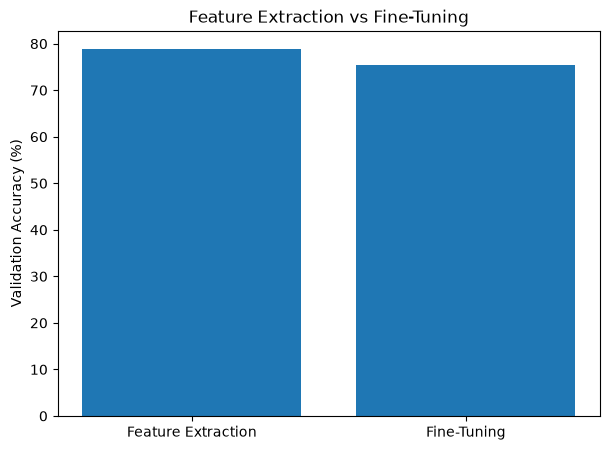

In [19]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Feature Extraction", "Fine-Tuning"],
    [feature_accuracy, fine_accuracy]
)

plt.ylabel("Validation Accuracy (%)")
plt.title("Feature Extraction vs Fine-Tuning")
plt.show()

In [20]:
if fine_accuracy > feature_accuracy:

    print("Conclusion:")
    print("Fine-tuning achieved higher validation accuracy.")
    print("Updating the last backbone block allowed the model")
    print("to adapt pretrained features to the CIFAR-10 dataset.")

elif feature_accuracy > fine_accuracy:

    print("Conclusion:")
    print("Feature extraction achieved higher validation accuracy.")
    print("The pretrained features were already useful for this dataset.")
    print("Fine-tuning may not have improved the learned features.")

else:

    print("Conclusion:")
    print("Both approaches achieved the same validation accuracy.")
    print("The pretrained features provided useful information,")
    print("and fine-tuning did not change the final accuracy.")

Conclusion:
Feature extraction achieved higher validation accuracy.
The pretrained features were already useful for this dataset.
Fine-tuning may not have improved the learned features.
